In [1]:

# Project 1.1 - Net Dollar Savings Analysis
# Fraud Detection under Concept Drift & Probability Calibration

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Project directory
BASE_DIR = r"D:\Fraud-Detection"

DATA_DIR = os.path.join(BASE_DIR, "data")
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

print("Net Dollar Savings Analysis")
print("-" * 45)
print("Project directory:", BASE_DIR)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)
print("Results directory:", RESULTS_DIR)

print("\nEnvironment ready!")


Net Dollar Savings Analysis
---------------------------------------------
Project directory: D:\Fraud-Detection
Data directory: D:\Fraud-Detection\data
Model directory: D:\Fraud-Detection\models
Results directory: D:\Fraud-Detection\results

Environment ready!


In [2]:

for folder in [DATA_DIR, MODEL_DIR, RESULTS_DIR]:

    print("\n" + "=" * 55)
    print("FOLDER:", folder)
    print("=" * 55)

    for root, dirs, files in os.walk(folder):
        level = root.replace(folder, "").count(os.sep)

        if level > 2:
            dirs[:] = []
            continue

        for file in files:
            print(os.path.relpath(
                os.path.join(root, file),
                BASE_DIR
            ))



FOLDER: D:\Fraud-Detection\data
data\raw\sample_submission.csv
data\raw\test_identity.csv
data\raw\test_transaction.csv
data\raw\train_identity.csv
data\raw\train_transaction.csv

FOLDER: D:\Fraud-Detection\models
models\ablation_full_model.txt
models\ablation_no_historical.txt
models\ablation_no_missingness.txt
models\ablation_no_time.txt
models\ablation_original_only.txt
models\bce_model.pkl
models\bce_model.txt
models\focal_alpha75_model.pkl
models\focal_alpha75_model.txt
models\isotonic_regression.pkl
models\lightgbm_baseline.pkl
models\platt_scaling.pkl

FOLDER: D:\Fraud-Detection\results
results\ablation_complete_comparison.csv
results\ablation_full_model_metrics.csv
results\ablation_no_historical_metrics.csv
results\ablation_no_missingness_metrics.csv
results\ablation_no_time_metrics.csv
results\ablation_original_only_metrics.csv
results\ablation_pr_auc_comparison.png
results\ablation_roc_auc_comparison.png
results\ablation_X_train_sample.parquet
results\ablation_X_val_sample.p

In [3]:

# Load saved test data and trained models

X_test = joblib.load(os.path.join(RESULTS_DIR, "X_test.pkl"))
y_test = joblib.load(os.path.join(RESULTS_DIR, "y_test.pkl"))

bce_model = joblib.load(os.path.join(MODEL_DIR, "bce_model.pkl"))
focal_model = joblib.load(os.path.join(MODEL_DIR, "focal_alpha75_model.pkl"))

# Load calibration models
bce_platt = joblib.load(os.path.join(RESULTS_DIR, "bce_platt_calibrator.pkl"))
bce_isotonic = joblib.load(os.path.join(RESULTS_DIR, "bce_isotonic_calibrator.pkl"))

focal_platt = joblib.load(os.path.join(
    RESULTS_DIR, "focal_alpha_0.75_platt_calibrator.pkl"
))
focal_isotonic = joblib.load(os.path.join(
    RESULTS_DIR, "focal_alpha_0.75_isotonic_calibrator.pkl"
))

print("TEST DATA INSPECTION")
print("-" * 45)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nFraud distribution:")
print(pd.Series(np.asarray(y_test).ravel()).value_counts())

print("\nFraud percentage:")
print(pd.Series(np.asarray(y_test).ravel()).mean() * 100)

print("\nTransactionAmt available:",
      "TransactionAmt" in X_test.columns)

print("\nTransactionAmt summary:")
if "TransactionAmt" in X_test.columns:
    print(X_test["TransactionAmt"].describe())
else:
    print("TransactionAmt is not present in X_test.")

print("\nModel feature counts:")
print("BCE:", getattr(bce_model, "n_features_in_", "Not available"))
print("Focal:", getattr(focal_model, "n_features_in_", "Not available"))


TEST DATA INSPECTION
---------------------------------------------
X_test shape: (88581, 441)
y_test shape: (88581,)

Fraud distribution:
0    85498
1     3083
Name: count, dtype: int64

Fraud percentage:
3.480430340592226

TransactionAmt available: True

TransactionAmt summary:
count    88581.000000
mean       137.148533
std        246.482355
min          0.499000
25%         44.000000
50%         68.500000
75%        117.000000
max       5366.820000
Name: TransactionAmt, dtype: float64

Model feature counts:
BCE: Not available
Focal: Not available


In [4]:

# Inspect saved model and calibration objects

objects = {
    "BCE Model": bce_model,
    "Focal Model": focal_model,
    "BCE Platt": bce_platt,
    "BCE Isotonic": bce_isotonic,
    "Focal Platt": focal_platt,
    "Focal Isotonic": focal_isotonic
}

for name, obj in objects.items():
    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)
    print("Class:", type(obj))
    print("Has predict_proba:", hasattr(obj, "predict_proba"))
    print("Has predict:", hasattr(obj, "predict"))
    print("Has transform:", hasattr(obj, "transform"))

# Inspect feature information
print("\nBCE feature information:")
if hasattr(bce_model, "feature_name_"):
    print("Feature count:", len(bce_model.feature_name_))
    print("First 10:", bce_model.feature_name_[:10])
elif hasattr(bce_model, "booster_"):
    print("Feature count:", bce_model.booster_.num_feature())
    print("First 10:", bce_model.booster_.feature_name()[:10])

print("\nFocal feature information:")
if hasattr(focal_model, "feature_name_"):
    print("Feature count:", len(focal_model.feature_name_))
elif hasattr(focal_model, "booster_"):
    print("Feature count:", focal_model.booster_.num_feature())



BCE Model
Class: <class 'lightgbm.basic.Booster'>
Has predict_proba: False
Has predict: True
Has transform: False

Focal Model
Class: <class 'lightgbm.basic.Booster'>
Has predict_proba: False
Has predict: True
Has transform: False

BCE Platt
Class: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Has predict_proba: True
Has predict: True
Has transform: False

BCE Isotonic
Class: <class 'sklearn.isotonic.IsotonicRegression'>
Has predict_proba: False
Has predict: True
Has transform: True

Focal Platt
Class: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Has predict_proba: True
Has predict: True
Has transform: False

Focal Isotonic
Class: <class 'sklearn.isotonic.IsotonicRegression'>
Has predict_proba: False
Has predict: True
Has transform: True

BCE feature information:

Focal feature information:


In [5]:

# Generate raw predictions from both LightGBM models

bce_raw = np.asarray(bce_model.predict(X_test)).ravel()
focal_raw = np.asarray(focal_model.predict(X_test)).ravel()

print("RAW PREDICTION INSPECTION")
print("-" * 50)

for name, predictions in [
    ("BCE", bce_raw),
    ("Focal Loss", focal_raw)
]:
    print(f"\n{name} predictions:")
    print("Shape:", predictions.shape)
    print("Minimum:", predictions.min())
    print("Maximum:", predictions.max())
    print("Mean:", predictions.mean())
    print("NaN values:", np.isnan(predictions).sum())
    print("First 10:", predictions[:10])

print("\nPrediction alignment:")
print("Test rows:", len(X_test))
print("BCE predictions:", len(bce_raw))
print("Focal predictions:", len(focal_raw))
print("Labels:", len(y_test))


RAW PREDICTION INSPECTION
--------------------------------------------------

BCE predictions:
Shape: (88581,)
Minimum: 0.0004954603860740304
Maximum: 0.9821347075533994
Mean: 0.035968978587713474
NaN values: 0
First 10: [0.00291882 0.00376685 0.01157006 0.00299725 0.00861858 0.00813236
 0.184967   0.00274032 0.02335138 0.00373072]

Focal Loss predictions:
Shape: (88581,)
Minimum: -2.4821907647778794
Maximum: 2.1390406678102094
Mean: -1.3386504617714752
NaN values: 0
First 10: [-1.94859118 -1.61109648 -1.23642131 -1.93876431 -1.40109109 -1.50834966
 -0.48823417 -1.90124762 -1.10112929 -1.8238375 ]

Prediction alignment:
Test rows: 88581
BCE predictions: 88581
Focal predictions: 88581
Labels: 88581


In [6]:

print("CALIBRATOR INSPECTION")
print("-" * 50)

print("\nBCE Platt coefficients:")
print(bce_platt.coef_)
print("Intercept:", bce_platt.intercept_)

print("\nBCE Isotonic input range:")
print("X threshold range:",
      bce_isotonic.X_thresholds_[0],
      "to",
      bce_isotonic.X_thresholds_[-1])

print("\nFocal Platt coefficients:")
print(focal_platt.coef_)
print("Intercept:", focal_platt.intercept_)

print("\nFocal Isotonic input range:")
print("X threshold range:",
      focal_isotonic.X_thresholds_[0],
      "to",
      focal_isotonic.X_thresholds_[-1])


CALIBRATOR INSPECTION
--------------------------------------------------

BCE Platt coefficients:
[[1.09983203]]
Intercept: [0.27554716]

BCE Isotonic input range:
X threshold range: -7.26389952277557 to 3.8367404738007695

Focal Platt coefficients:
[[2.8565595]]
Intercept: [-0.71522655]

Focal Isotonic input range:
X threshold range: -2.454659703061907 to 2.132214594465939


In [7]:

from scipy.special import expit, logit

# 1. Convert BCE probabilities into logits
EPSILON = 1e-7

bce_logits = logit(
    np.clip(bce_raw, EPSILON, 1 - EPSILON)
)

# 2. Convert Focal Loss logits into probabilities
focal_raw_prob = expit(focal_raw)

# 3. Apply Platt Scaling
bce_platt_prob = bce_platt.predict_proba(
    bce_logits.reshape(-1, 1)
)[:, 1]

focal_platt_prob = focal_platt.predict_proba(
    focal_raw.reshape(-1, 1)
)[:, 1]

# 4. Apply Isotonic Regression
bce_isotonic_prob = bce_isotonic.predict(bce_logits)

focal_isotonic_prob = focal_isotonic.predict(focal_raw)

# 5. Store all prediction strategies
predictions = {
    "BCE_Raw": bce_raw,
    "BCE_Platt": bce_platt_prob,
    "BCE_Isotonic": bce_isotonic_prob,
    "Focal_Raw": focal_raw_prob,
    "Focal_Platt": focal_platt_prob,
    "Focal_Isotonic": focal_isotonic_prob
}

# 6. Verify predictions
print("CALIBRATED PREDICTION SUMMARY")
print("-" * 60)

for name, pred in predictions.items():
    print(f"\n{name}")
    print("Minimum:", np.min(pred))
    print("Maximum:", np.max(pred))
    print("Mean:", np.mean(pred))
    print("NaN:", np.isnan(pred).sum())
    print("Outside [0,1]:",
          np.sum((pred < 0) | (pred > 1)))

print("\nAll prediction arrays generated.")


CALIBRATED PREDICTION SUMMARY
------------------------------------------------------------

BCE_Raw
Minimum: 0.0004954603860740304
Maximum: 0.9821347075533994
Mean: 0.035968978587713474
NaN: 0
Outside [0,1]: 0

BCE_Platt
Minimum: 0.000305377924020343
Maximum: 0.9908284001528507
Mean: 0.0367297562014938
NaN: 0
Outside [0,1]: 0

BCE_Isotonic
Minimum: 0.0
Maximum: 1.0
Mean: 0.03652618886397695
NaN: 0
Outside [0,1]: 0

Focal_Raw
Minimum: 0.07711614254831156
Maximum: 0.8946402189193399
Mean: 0.2191919332953895
NaN: 0
Outside [0,1]: 0

Focal_Platt
Minimum: 0.0004072189887682158
Maximum: 0.9954816076701443
Mean: 0.03641298984331201
NaN: 0
Outside [0,1]: 0

Focal_Isotonic
Minimum: 0.0
Maximum: 1.0
Mean: 0.03633442474511442
NaN: 0
Outside [0,1]: 0

All prediction arrays generated.


In [8]:

from sklearn.metrics import brier_score_loss, log_loss

y_true = np.asarray(y_test).ravel().astype(int)

calibration_results = []

for name, pred in predictions.items():

    # BCE_Raw and calibrated predictions are probabilities.
    # Focal_Raw was converted using sigmoid above.
    pred = np.clip(pred, EPSILON, 1 - EPSILON)

    calibration_results.append({
        "Model": name,
        "Brier Score": brier_score_loss(y_true, pred),
        "Log Loss": log_loss(y_true, pred)
    })

calibration_df = pd.DataFrame(calibration_results)

print(calibration_df.to_string(index=False))

calibration_df.to_csv(
    os.path.join(RESULTS_DIR, "net_dollar_calibration_metrics.csv"),
    index=False
)


         Model  Brier Score  Log Loss
       BCE_Raw     0.022974  0.095464
     BCE_Platt     0.023073  0.095750
  BCE_Isotonic     0.023201  0.097762
     Focal_Raw     0.060528  0.264172
   Focal_Platt     0.023240  0.096388
Focal_Isotonic     0.023394  0.097497


In [9]:
for filename in [
    "final_test_comparison.csv",
    "final_threshold_selection.csv",
    "thursday_calibration_evaluation.csv"
]:
    path = os.path.join(RESULTS_DIR, filename)

    print("\n", "=" * 60)
    print(filename)
    print("=" * 60)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.head())
        print("Columns:", df.columns.tolist())


final_test_comparison.csv
              Model  Threshold   ROC-AUC    PR-AUC  Precision    Recall  \
0               BCE       0.16  0.888311  0.503301   0.422193  0.512163   
1  Focal Alpha 0.75       0.33  0.889039  0.493521   0.623618  0.402530   

   F1 Score  Brier Score  Log Loss  
0  0.462846     0.022974  0.095464  
1  0.489257     0.023240  0.096388  
Columns: ['Model', 'Threshold', 'ROC-AUC', 'PR-AUC', 'Precision', 'Recall', 'F1 Score', 'Brier Score', 'Log Loss']

final_threshold_selection.csv
              Model  Threshold  Precision    Recall  F1 Score
0               BCE       0.16   0.417920  0.460317  0.438095
1  Focal Alpha 0.75       0.33   0.597274  0.332643  0.427305
Columns: ['Model', 'Threshold', 'Precision', 'Recall', 'F1 Score']

thursday_calibration_evaluation.csv
                           Model  Mean Predicted Probability  \
0               BCE Uncalibrated                    0.031427   
1                      BCE Platt                    0.031904   
2  Focal

In [10]:

from scipy.special import expit, logit

# Ground truth and transaction amounts
y_true = np.asarray(y_test).ravel().astype(int)
amounts = X_test["TransactionAmt"].to_numpy(dtype=float)

# Generate raw model predictions
bce_raw = np.asarray(bce_model.predict(X_test)).ravel()
focal_raw = np.asarray(focal_model.predict(X_test)).ravel()

# Convert BCE probabilities to logits for calibration
EPSILON = 1e-7
bce_logits = logit(np.clip(bce_raw, EPSILON, 1 - EPSILON))

# Convert focal logits to probabilities
focal_raw_prob = expit(focal_raw)

# Generate calibrated probabilities
predictions = {
    "BCE Uncalibrated": bce_raw,
    "BCE Platt": bce_platt.predict_proba(
        bce_logits.reshape(-1, 1)
    )[:, 1],
    "BCE Isotonic": bce_isotonic.predict(bce_logits),

    "Focal Uncalibrated": focal_raw_prob,
    "Focal Platt": focal_platt.predict_proba(
        focal_raw.reshape(-1, 1)
    )[:, 1],
    "Focal Isotonic": focal_isotonic.predict(focal_raw)
}

# Verify inputs
assert len(y_true) == len(amounts) == len(bce_raw) == len(focal_raw)
assert np.isfinite(amounts).all()
assert (amounts >= 0).all()

for name, p in predictions.items():
    assert np.isfinite(p).all(), f"Invalid predictions: {name}"
    assert ((p >= 0) & (p <= 1)).all(), f"Invalid probabilities: {name}"

print("All six probability arrays generated successfully.")
print("Test transactions:", len(y_true))
print("Total transaction amount: $", round(amounts.sum(), 2))
print("Total actual fraud amount: $", round(amounts[y_true == 1].sum(), 2))
print("All probability and alignment checks passed.")


All six probability arrays generated successfully.
Test transactions: 88581
Total transaction amount: $ 12148754.19
Total actual fraud amount: $ 469608.52
All probability and alignment checks passed.


In [11]:

# Financial decision policy

FP_COST = 15.0

def evaluate_financial_policy(y_true, amounts, probabilities,
                              strategy, fixed_threshold=None):

    if fixed_threshold is None:
        # Runbook expected-loss policy
        declined = (probabilities * amounts) > FP_COST
    else:
        # Fixed probability threshold baseline
        declined = probabilities > fixed_threshold

    actual_fraud = (y_true == 1)
    actual_legitimate = (y_true == 0)

    tp = declined & actual_fraud
    fp = declined & actual_legitimate
    fn = (~declined) & actual_fraud
    tn = (~declined) & actual_legitimate

    fraud_prevented = amounts[tp].sum()
    missed_fraud_loss = amounts[fn].sum()
    false_positive_cost = fp.sum() * FP_COST

    net_savings = fraud_prevented - false_positive_cost

    total_fraud_amount = amounts[actual_fraud].sum()

    return {
        "Strategy": strategy,
        "Declined Transactions": int(declined.sum()),
        "True Positives": int(tp.sum()),
        "False Positives": int(fp.sum()),
        "False Negatives": int(fn.sum()),
        "True Negatives": int(tn.sum()),
        "Fraud Prevented ($)": fraud_prevented,
        "Missed Fraud Loss ($)": missed_fraud_loss,
        "False Positive Cost ($)": false_positive_cost,
        "Net Dollar Savings ($)": net_savings,
        "Savings vs Approve All (%)": (
            net_savings / total_fraud_amount * 100
            if total_fraud_amount > 0 else 0
        )
    }


financial_results = []

# Runbook $15 policy: all six probability strategies
for name, probability in predictions.items():
    result = evaluate_financial_policy(
        y_true,
        amounts,
        probability,
        name + " - $15 Policy"
    )
    financial_results.append(result)

# Fixed 0.5 probability baselines
for name, probability in [
    ("BCE", predictions["BCE Uncalibrated"]),
    ("Focal", predictions["Focal Uncalibrated"])
]:
    result = evaluate_financial_policy(
        y_true,
        amounts,
        probability,
        name + " - Fixed 0.5",
        fixed_threshold=0.5
    )
    financial_results.append(result)

financial_df = pd.DataFrame(financial_results)

money_columns = [
    "Fraud Prevented ($)",
    "Missed Fraud Loss ($)",
    "False Positive Cost ($)",
    "Net Dollar Savings ($)"
]

financial_df[money_columns] = financial_df[money_columns].round(2)

print("NET DOLLAR SAVINGS - FINANCIAL COMPARISON")
print("=" * 100)

print(financial_df.to_string(index=False))

financial_df.to_csv(
    os.path.join(RESULTS_DIR, "net_dollar_savings_comparison.csv"),
    index=False
)

print("\nResults saved successfully!")


NET DOLLAR SAVINGS - FINANCIAL COMPARISON
                       Strategy  Declined Transactions  True Positives  False Positives  False Negatives  True Negatives  Fraud Prevented ($)  Missed Fraud Loss ($)  False Positive Cost ($)  Net Dollar Savings ($)  Savings vs Approve All (%)
  BCE Uncalibrated - $15 Policy                   6155            1367             4788             1716           80710            343320.39              126288.13                  71820.0               271500.39                   57.814196
         BCE Platt - $15 Policy                   6172            1421             4751             1662           80747            343104.96              126503.57                  71265.0               271839.96                   57.886504
      BCE Isotonic - $15 Policy                   5999            1416             4583             1667           80915            341403.18              128205.34                  68745.0               272658.18                   

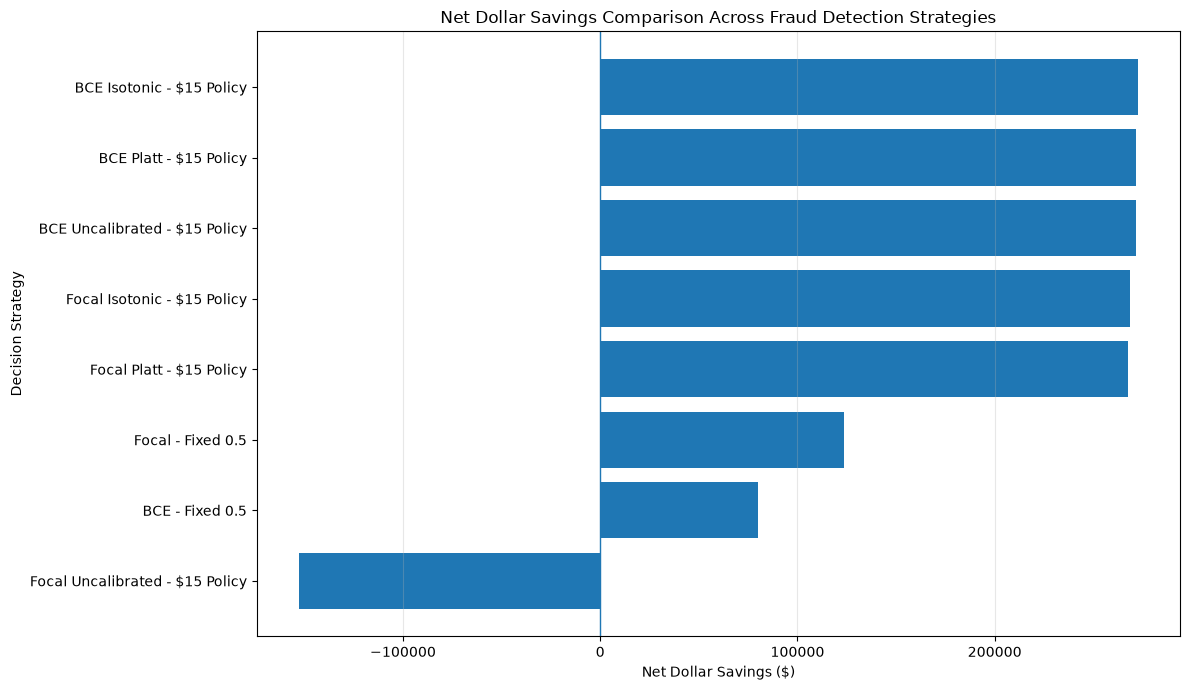

Chart saved: D:\Fraud-Detection\results\net_dollar_savings_comparison.png


In [12]:

# Net Dollar Savings comparison chart

plot_df = financial_df.sort_values(
    "Net Dollar Savings ($)",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_df["Strategy"],
    plot_df["Net Dollar Savings ($)"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Net Dollar Savings ($)")
plt.ylabel("Decision Strategy")
plt.title("Net Dollar Savings Comparison Across Fraud Detection Strategies")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

chart_path = os.path.join(
    RESULTS_DIR,
    "net_dollar_savings_comparison.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)


In [13]:

# Save final experiment summary

best_result = financial_df.loc[
    financial_df["Net Dollar Savings ($)"].idxmax()
]

summary = pd.DataFrame([{
    "Best Strategy": best_result["Strategy"],
    "Net Dollar Savings ($)": best_result["Net Dollar Savings ($)"],
    "Fraud Prevented ($)": best_result["Fraud Prevented ($)"],
    "Missed Fraud Loss ($)": best_result["Missed Fraud Loss ($)"],
    "False Positive Cost ($)": best_result["False Positive Cost ($)"],
    "Declined Transactions": best_result["Declined Transactions"],
    "False Positives": best_result["False Positives"],
    "False Negatives": best_result["False Negatives"],
    "False Positive Cost Assumption ($)": FP_COST,
    "Test Transactions": len(y_true)
}])

summary_path = os.path.join(
    RESULTS_DIR,
    "net_dollar_savings_final_summary.csv"
)

summary.to_csv(summary_path, index=False)

print("FINAL EXPERIMENT SUMMARY")
print("=" * 60)
print(summary.to_string(index=False))

print("\nSaved files:")
print("1. net_dollar_savings_comparison.csv")
print("2. net_dollar_savings_comparison.png")
print("3. net_dollar_savings_final_summary.csv")


FINAL EXPERIMENT SUMMARY
            Best Strategy  Net Dollar Savings ($)  Fraud Prevented ($)  Missed Fraud Loss ($)  False Positive Cost ($)  Declined Transactions  False Positives  False Negatives  False Positive Cost Assumption ($)  Test Transactions
BCE Isotonic - $15 Policy               272658.18            341403.18              128205.34                  68745.0                   5999             4583             1667                                15.0              88581

Saved files:
1. net_dollar_savings_comparison.csv
2. net_dollar_savings_comparison.png
3. net_dollar_savings_final_summary.csv


In [14]:

# Inspect existing error-analysis files

files_to_inspect = [
    "thursday_false_negative_feature_comparison.csv",
    "thursday_false_negative_statistical_tests.csv",
    "conditional_fraud_statistical_tests.csv",
    "id31_browser_fraud_analysis.csv",
    "feature_importance.csv",
    "shap_feature_comparison.csv"
]

for filename in files_to_inspect:

    path = os.path.join(RESULTS_DIR, filename)

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(5).to_string(index=False))
    else:
        print("File not found")



thursday_false_negative_feature_comparison.csv
Shape: (18, 7)
Columns: ['Group', 'Feature', 'Feature Type', 'Mean', 'Median', 'Missing Percentage', 'Most Common Value']
         Group        Feature Feature Type       Mean  Median  Missing Percentage Most Common Value
Missed by Both TransactionAmt    Numerical 152.676230  86.564            0.000000               NaN
Missed by Both  P_emaildomain  Categorical        NaN     NaN           18.414322         gmail.com
Missed by Both             C1    Numerical  20.538363   2.000            0.000000               NaN
Missed by Both            C13    Numerical  30.489770   3.000            0.000000               NaN
Missed by Both             C5    Numerical   4.198210   0.000            0.000000               NaN

thursday_false_negative_statistical_tests.csv
Shape: (10, 6)
Columns: ['Feature', 'Comparison', 'P-value', 'Significant at 0.05', 'Adjusted P-value', 'Significant After Correction']
       Feature                          Compari

In [15]:

# ERROR-SLICE ANALYSIS
# Selected strategy: BCE Isotonic + $15 policy

best_prob = predictions["BCE Isotonic"]

declined = (best_prob * amounts) > 15

actual_fraud = y_true == 1
false_negatives = actual_fraud & (~declined)
false_positives = (~actual_fraud) & declined

# 1. Extract all missed fraud transactions
fn_indices = np.where(false_negatives)[0]

fn_data = X_test.iloc[fn_indices].copy()

fn_data["Actual_Fraud"] = y_true[fn_indices]
fn_data["Predicted_Probability"] = best_prob[fn_indices]
fn_data["Transaction_Amount"] = amounts[fn_indices]
fn_data["Expected_Fraud_Loss"] = (
    best_prob[fn_indices] * amounts[fn_indices]
)

# 2. Identify the 10 costliest missed fraud transactions
top_10_fn = fn_data.sort_values(
    "Transaction_Amount",
    ascending=False
).head(10)

top_10_columns = [
    "Transaction_Amount",
    "Predicted_Probability",
    "Expected_Fraud_Loss"
]

top_10_fn[top_10_columns].to_csv(
    os.path.join(RESULTS_DIR, "top_10_costliest_false_negatives.csv"),
    index=False
)

print("TOP 10 COSTLIEST MISSED FRAUD TRANSACTIONS")
print("=" * 75)
print(top_10_fn[top_10_columns].to_string(index=False))

# 3. Create transaction amount slices
slice_data = pd.DataFrame({
    "Actual": y_true,
    "Predicted": declined.astype(int),
    "Amount": amounts,
    "Probability": best_prob
})

slice_data["Amount Group"] = pd.cut(
    slice_data["Amount"],
    bins=[0, 50, 100, 250, 500, np.inf],
    labels=["0-50", "50-100", "100-250", "250-500", "500+"],
    include_lowest=True
)

slice_results = []

for group, data in slice_data.groupby(
    "Amount Group", observed=False
):

    fraud_count = int(data["Actual"].sum())
    fn_count = int((
        (data["Actual"] == 1) &
        (data["Predicted"] == 0)
    ).sum())

    fp_count = int((
        (data["Actual"] == 0) &
        (data["Predicted"] == 1)
    ).sum())

    slice_results.append({
        "Amount Group": str(group),
        "Transactions": len(data),
        "Fraud Transactions": fraud_count,
        "False Negatives": fn_count,
        "False Negatives %": (
            fn_count / fraud_count * 100
            if fraud_count else 0
        ),
        "False Positives": fp_count
    })

slice_df = pd.DataFrame(slice_results)

slice_df.to_csv(
    os.path.join(RESULTS_DIR, "error_slice_amount_analysis.csv"),
    index=False
)

print("\nERROR ANALYSIS BY TRANSACTION AMOUNT")
print("=" * 75)
print(slice_df.to_string(index=False))

print("\nTotal False Negatives:", len(fn_indices))
print("Total False Positives:", int(false_positives.sum()))
print("Missed fraud dollar amount:", round(
    amounts[false_negatives].sum(), 2
))

print("\nError-slice analysis completed.")


TOP 10 COSTLIEST MISSED FRAUD TRANSACTIONS
 Transaction_Amount  Predicted_Probability  Expected_Fraud_Loss
            1949.69               0.003697             7.207726
            1504.47               0.009091            13.677000
            1402.85               0.007614            10.680664
            1402.85               0.009302            13.049767
            1384.95               0.007614            10.544382
            1224.00               0.009091            11.127273
            1044.95               0.007614             7.955776
             884.00               0.014414            12.742342
             680.45               0.014414             9.808288
             611.95               0.007614             4.659110

ERROR ANALYSIS BY TRANSACTION AMOUNT
Amount Group  Transactions  Fraud Transactions  False Negatives  False Negatives %  False Positives
        0-50         29855                1257              881          70.087510               77
      50-100   

In [17]:

# ==========================================
# FINAL ERROR-SLICE ANALYSIS REPORT
# ==========================================

from pathlib import Path

# 1. Prepare summary values
total_transactions = len(y_true)
total_fraud = int(np.sum(actual_fraud))
total_fn = int(np.sum(false_negatives))
total_fp = int(np.sum(false_positives))

missed_fraud_amount = float(amounts[false_negatives].sum())
prevented_fraud_amount = float(amounts[declined & actual_fraud].sum())

# 2. Convert DataFrames to Markdown without tabulate
def dataframe_to_markdown(df):
    headers = [str(col) for col in df.columns]
    rows = df.astype(str).values.tolist()

    header_line = "| " + " | ".join(headers) + " |"
    separator = "| " + " | ".join(["---"] * len(headers)) + " |"

    data_lines = [
        "| " + " | ".join(row) + " |"
        for row in rows
    ]

    return "\n".join([header_line, separator] + data_lines)


# 3. Prepare amount-slice table
amount_slice_table = dataframe_to_markdown(slice_df)

# 4. Prepare top 10 costly false negatives
top_10_table = dataframe_to_markdown(
    top_10_fn[
        [
            "Transaction_Amount",
            "Predicted_Probability",
            "Expected_Fraud_Loss"
        ]
    ].round(4)
)

# 5. Create report
report = f"""
# Fraud Detection – Error Slice Analysis Report

## 1. Evaluation Overview

- Total test transactions: {total_transactions:,}
- Actual fraudulent transactions: {total_fraud:,}
- False negatives: {total_fn:,}
- False positives: {total_fp:,}
- Fraud amount prevented: ${prevented_fraud_amount:,.2f}
- Missed fraud amount: ${missed_fraud_amount:,.2f}

## 2. Error Analysis by Transaction Amount

{amount_slice_table}

The model missed a higher proportion of fraudulent transactions
in lower transaction-amount groups. The false-negative rate
decreased as transaction amount increased in this test set.

## 3. Ten Costliest Missed Fraudulent Transactions

{top_10_table}

These are actual fraudulent transactions that the selected
BCE Isotonic model's $15 expected-loss policy approved.

## 4. Interpretation

The results show a trade-off between preventing fraud and
avoiding unnecessary declines.

Lower-value transactions had a higher false-negative rate.
Higher-value transactions were more likely to be declined
under the expected-loss policy.

This is an observation from the test data and does not
establish that transaction amount causes fraud or model errors.

## 5. Selected Decision Policy

The selected strategy is BCE Isotonic calibration with the
$15 expected-loss decision policy:

Decline a transaction when:

Predicted Fraud Probability x Transaction Amount > $15

## 6. Output Files

- error_slice_analysis_report.md
- error_slice_analysis_report.csv
- top_10_costliest_false_negatives.csv
"""

# 6. Save report
report_path = RESULTS_DIR / "error_slice_analysis_report.md"
report_path.write_text(report, encoding="utf-8")

# 7. Save supporting tables
slice_df.to_csv(
    RESULTS_DIR / "error_slice_analysis_report.csv",
    index=False
)

top_10_fn[
    [
        "Transaction_Amount",
        "Predicted_Probability",
        "Expected_Fraud_Loss"
    ]
].to_csv(
    RESULTS_DIR / "top_10_costliest_false_negatives.csv",
    index=False
)

print("Error-slice report created successfully.")
print("Saved to:", report_path)
print("\nReport preview:\n")
print(report)


TypeError: unsupported operand type(s) for /: 'str' and 'str'

In [18]:
from pathlib import Path

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("Directory exists:", RESULTS_DIR.exists())

Results directory: D:\Fraud-Detection\results
Directory exists: True


In [19]:
# Save the Markdown report
report_path = RESULTS_DIR / "error_slice_analysis_report.md"
report_path.write_text(report, encoding="utf-8")

# Save the amount-based error analysis
slice_df.to_csv(
    RESULTS_DIR / "error_slice_analysis_report.csv",
    index=False
)

# Save the 10 costliest false negatives
top_10_fn[
    [
        "Transaction_Amount",
        "Predicted_Probability",
        "Expected_Fraud_Loss"
    ]
].to_csv(
    RESULTS_DIR / "top_10_costliest_false_negatives.csv",
    index=False
)

print("All error-slice reports saved successfully!")
print("Location:", RESULTS_DIR)
print("Files:")
print("- error_slice_analysis_report.md")
print("- error_slice_analysis_report.csv")
print("- top_10_costliest_false_negatives.csv")

All error-slice reports saved successfully!
Location: D:\Fraud-Detection\results
Files:
- error_slice_analysis_report.md
- error_slice_analysis_report.csv
- top_10_costliest_false_negatives.csv


In [20]:
from pathlib import Path

files_to_check = [
    "error_slice_analysis_report.md",
    "error_slice_analysis_report.csv",
    "top_10_costliest_false_negatives.csv",
    "net_dollar_savings_comparison.csv",
    "net_dollar_savings_comparison.png",
    "net_dollar_savings_final_summary.csv"
]

print("FINAL OUTPUT VERIFICATION\n")

for filename in files_to_check:
    file_path = RESULTS_DIR / filename

    if file_path.exists():
        print(f"[OK] {filename} | {file_path.stat().st_size:,} bytes")
    else:
        print(f"[MISSING] {filename}")

FINAL OUTPUT VERIFICATION

[OK] error_slice_analysis_report.md | 2,285 bytes
[OK] error_slice_analysis_report.csv | 314 bytes
[OK] top_10_costliest_false_negatives.csv | 528 bytes
[OK] net_dollar_savings_comparison.csv | 1,070 bytes
[OK] net_dollar_savings_comparison.png | 146,345 bytes
[OK] net_dollar_savings_final_summary.csv | 302 bytes
